# 4.6.- Taller práctico de Redes Neuronales Artificiales (ANN)

Este notebook está diseñado como una **clase práctica progresiva** para consolidar los conceptos del Tema 4 de ANN y enlazar con los notebooks 4.1–4.5.

### Objetivos de la sesión
- Entender qué puede y qué no puede resolver un **perceptrón**.
- Visualizar y comparar **sigmoide, tanh, ReLU y Leaky ReLU**.
- Construir una **MLP con Keras** para clasificación no lineal.
- Interpretar **loss, accuracy, épocas, batch size y learning rate**.
- Detectar **underfitting y overfitting**.
- Aplicar **EarlyStopping, Dropout y BatchNormalization**.
- Resolver un problema **multiclase con Softmax**.
- Comparar configuraciones de **hiperparámetros** y guardar/cargar el mejor modelo.

**Duración orientativa:** 90–120 minutos.  
**Nivel:** guiado al principio y cada vez más autónomo.


## 0. Preparación

Ejecuta esta celda antes de comenzar. Se fijan semillas para que los resultados sean reproducibles.


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

from sklearn.datasets import make_moons, make_blobs
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
tf.random.set_seed(42)

print('TensorFlow:', tf.__version__)


TensorFlow: 2.22.0-rc0


---
## (No hacer) Ejercicio 1 — De TLU a perceptrón: puertas lógicas

Una TLU calcula una suma ponderada y aplica un **umbral**. En clase se ha visto que puede representar funciones lógicas linealmente separables como AND, OR y NAND.

### 1A. Completa una TLU genérica
Implementa una función `TLU(x, w, theta)` que devuelva 1 cuando $w^T x \geq 	heta$ y 0 en caso contrario.


In [34]:
def TLU(x, w, theta=0):
    # TODO: calcula la suma ponderada y aplica el umbral
    pass

entradas = [(0,0), (0,1), (1,0), (1,1)]

# TODO: elige pesos y umbral para AND
w_and = [...]
theta_and = ...
print('AND:', [TLU(x, w_and, theta_and) for x in entradas])

# TODO: repite para OR y NAND


AND: [None, None, None, None]


### 1B. Pregunta de razonamiento
¿Puedes encontrar **una única recta** que separe correctamente las salidas 0 y 1 de XOR? Justifica tu respuesta antes de pasar al siguiente ejercicio.


---
## Ejercicio 2 — Perceptrón de Rosenblatt y la limitación de XOR

Entrena un `Perceptron` de scikit-learn para AND, OR y XOR. Compara las predicciones.


In [53]:
# Entrenamos un Perceptron para cada puerta y comparamos predicciones y accuracy.
salidas = {"AND": y_and, "OR": y_or, "XOR": y_xor}

for nombre, y in salidas.items():
    modelo = Perceptron(max_iter=1000, eta0=0.1, tol=0.001, random_state=42)
    modelo.fit(X_logic, y)
    predicciones = modelo.predict(X_logic)
    print(f"{nombre}: predicciones={predicciones}, accuracy={accuracy_score(y, predicciones):.2f}")

AND: predicciones=[0 0 0 1], accuracy=1.00
OR: predicciones=[0 1 1 1], accuracy=1.00
XOR: predicciones=[0 0 0 0], accuracy=0.50


**Interpreta:** si XOR no llega al 100%, no es un fallo de entrenamiento: el problema no es linealmente separable. Esta limitación motiva el uso de **capas ocultas + activaciones no lineales**.


---
## (No hacer) Ejercicio 3 — Funciones de activación y sus derivadas

Representa en el mismo rango las funciones:
- Sigmoide
- tanh
- ReLU
- Leaky ReLU ($lpha=0.1$)

Después representa también sus derivadas aproximadas o analíticas. El objetivo es relacionar la forma de la derivada con el **vanishing gradient**.


In [36]:
x = np.linspace(-6, 6, 500)

# TODO: calcula las cuatro funciones
sigmoid = ...
tanh = ...
relu = ...
leaky_relu = ...

# TODO: dibuja las cuatro curvas

# TODO: calcula/dibuja sus derivadas


### Preguntas rápidas
1. ¿En qué zonas la derivada de la sigmoide es casi 0?  
2. ¿Por qué eso puede ralentizar el aprendizaje en capas iniciales?  
3. ¿Qué ventaja aporta Leaky ReLU frente a ReLU cuando $x<0$?


---
## Ejercicio 4 — De frontera lineal a MLP: resolver `make_moons`

Crearemos un dataset no lineal. Primero probaremos un modelo sin capa oculta y después una MLP.


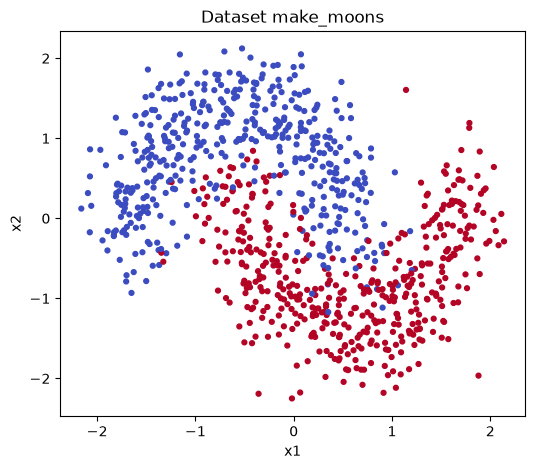

In [37]:
X, y = make_moons(n_samples=1200, noise=0.22, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

plt.figure(figsize=(6,5))
plt.scatter(X_train[:,0], X_train[:,1], c=y_train, s=12, cmap='coolwarm')
plt.title('Dataset make_moons')
plt.xlabel('x1'); plt.ylabel('x2'); plt.show()


### 4A. Modelo lineal
Crea una red con **una sola neurona sigmoide** de salida. Es equivalente a una frontera lineal.


In [38]:
# Una sola neurona sigmoide: frontera de decisión lineal.
linear_model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(1, activation="sigmoid")
])

linear_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
linear_model.fit(X_train, y_train, epochs=40, verbose=0)

linear_loss, linear_acc = linear_model.evaluate(X_test, y_test, verbose=0)
print(f"Modelo lineal — loss test: {linear_loss:.4f} | accuracy test: {linear_acc:.4f}")


Modelo lineal — loss test: 0.4601 | accuracy test: 0.7233


### 4B. MLP
Añade al menos **dos capas ocultas con ReLU**. Mantén una única salida sigmoide.


In [39]:
# MLP 2 -> 16 -> 16 -> 1 para aprender una frontera no lineal.
mlp = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

mlp.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = mlp.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    verbose=0
)

mlp_loss, mlp_acc = mlp.evaluate(X_test, y_test, verbose=0)
print(f"MLP — loss test: {mlp_loss:.4f} | accuracy test: {mlp_acc:.4f}")


MLP — loss test: 0.1040 | accuracy test: 0.9600


### 4C. Curvas de aprendizaje
Representa `loss` y `val_loss`. Identifica si el modelo todavía está aprendiendo, se ha estabilizado o empieza a sobreajustar.


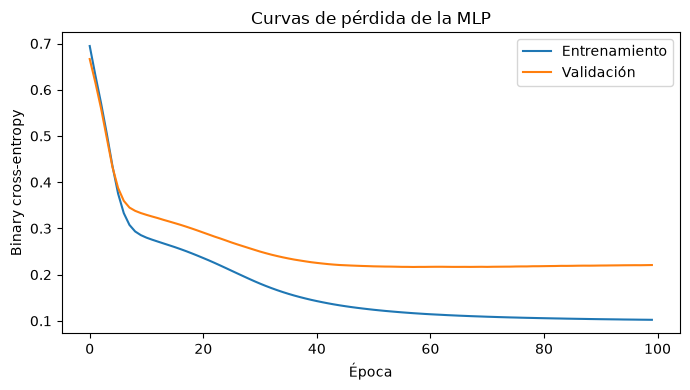

In [40]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.title("Curvas de pérdida de la MLP")
plt.xlabel("Época")
plt.ylabel("Binary cross-entropy")
plt.legend()
plt.tight_layout()
plt.show()

---
## Ejercicio 5 — Learning rate: demasiado pequeño, adecuado o demasiado grande

Entrena la **misma arquitectura** con tres tasas de aprendizaje:
- `0.0001`
- `0.001`
- `0.1`

Compara la pérdida de validación. Mantén todo lo demás constante.


In [ ]:
def train_with_lr(lr):
    # Misma arquitectura del ejercicio 4; solo cambia la tasa de aprendizaje.
    model = keras.Sequential([
        keras.Input(shape=(2,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=100,
        verbose=0
    )

learning_rates = [1e-4, 1e-3, 1e-1]
histories = {lr: train_with_lr(lr) for lr in learning_rates}

plt.figure(figsize=(7, 4))
for lr, history_lr in histories.items():
    plt.plot(history_lr.history["val_loss"], label=f"lr={lr}")
plt.title("Comparación de learning rate")
plt.xlabel("Época")
plt.ylabel("Validation loss")
plt.legend()
plt.tight_layout()
plt.show()


**Interpretación:** con `learning_rate=0.0001`, el aprendizaje suele ser lento y la pérdida baja poco en el mismo número de épocas. `0.001` suele permitir una convergencia más rápida y estable. Con `0.1`, los pasos pueden ser demasiado grandes: la pérdida puede oscilar o no disminuir de forma estable. La curva de validación permite comparar estas diferencias.


---
## Ejercicio 6 — Overfitting y regularización

Vamos a reducir el conjunto de entrenamiento para hacer más fácil que una red grande memorice los datos. Compararemos:
1. Red grande sin regularización.
2. Red con `Dropout`, `BatchNormalization` y `EarlyStopping`.


In [42]:
# Subconjunto pequeño para provocar sobreajuste con más facilidad
X_small = X_train[:180]
y_small = y_train[:180]


In [ ]:
# Modelo grande sin regularización: se entrena sobre el subconjunto pequeño.
large_model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])
large_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_large = large_model.fit(
    X_small, y_small, validation_split=0.2, epochs=250, verbose=0
)

# Mismo tamaño, con BatchNormalization, Dropout y parada temprana.
regularized_model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.35),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.35),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.35),
    layers.Dense(1, activation="sigmoid")
])
regularized_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=12, restore_best_weights=True
)
history_regularized = regularized_model.fit(
    X_small, y_small, validation_split=0.2, epochs=250,
    callbacks=[early_stop], verbose=0
)

# Curvas para comparar ajuste y generalización.
plt.figure(figsize=(8, 5))
plt.plot(history_large.history["loss"], label="Grande — entrenamiento")
plt.plot(history_large.history["val_loss"], label="Grande — validación")
plt.plot(history_regularized.history["loss"], label="Regularizado — entrenamiento")
plt.plot(history_regularized.history["val_loss"], label="Regularizado — validación")
plt.title("Overfitting y regularización")
plt.xlabel("Época")
plt.ylabel("Binary cross-entropy")
plt.legend()
plt.tight_layout()
plt.show()

# Evaluate devuelve loss y accuracy, en ese orden.
large_test_loss, large_test_acc = large_model.evaluate(X_test, y_test, verbose=0)
reg_test_loss, reg_test_acc = regularized_model.evaluate(X_test, y_test, verbose=0)
print(f"Grande: {len(history_large.history['loss'])} épocas | test accuracy={large_test_acc:.3f}")
print(f"Regularizado: {len(history_regularized.history['loss'])} épocas | test accuracy={reg_test_acc:.3f}")


### Cómo interpretar los resultados
- Hay una señal de sobreajuste cuando `loss` de entrenamiento sigue bajando y `val_loss` deja de bajar o empieza a subir.
- El número de épocas impresas indica si EarlyStopping paró antes del máximo de 250. Al restaurar los mejores pesos, el modelo conserva los de menor `val_loss`.
- Dropout no tiene por qué reducir la pérdida de entrenamiento: durante el entrenamiento desactiva neuronas al azar y dificulta memorizar; se busca mejorar la generalización.


---
## Ejercicio 7 — Clasificación multiclase con Softmax

Construye un clasificador para **3 clases**. La capa de salida debe tener 3 neuronas con `softmax`.


In [44]:
X3, y3 = make_blobs(
    n_samples=1200, centers=3, n_features=2,
    cluster_std=2.0, random_state=7
)
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.25, stratify=y3, random_state=42
)
scaler3 = StandardScaler()
X3_train = scaler3.fit_transform(X3_train)
X3_test = scaler3.transform(X3_test)


In [ ]:
# Clasificador multiclase 2 -> 16 -> 3 con salida softmax.
softmax_model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(3, activation="softmax")
])

softmax_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
softmax_model.fit(
    X3_train, y3_train, validation_split=0.2, epochs=50, verbose=0
)

# Cada fila contiene las probabilidades estimadas para las tres clases.
probabilidades = softmax_model.predict(X3_test[:5], verbose=0)
print("Probabilidades de las primeras 5 muestras:\n", probabilidades)
print("Suma por fila:", probabilidades.sum(axis=1))

# Evaluación y matriz de confusión sobre el conjunto de test.
test_loss, test_acc = softmax_model.evaluate(X3_test, y3_test, verbose=0)
y3_pred = np.argmax(softmax_model.predict(X3_test, verbose=0), axis=1)
cm = confusion_matrix(y3_test, y3_pred)
print(f"Test accuracy: {test_acc:.3f}")
print("Matriz de confusión:\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap="Blues")
plt.title("Matriz de confusión — Softmax")
plt.tight_layout()
plt.show()


---
## Ejercicio 8 — Mini búsqueda de hiperparámetros

Sin usar todavía Keras Tuner, prueba varias configuraciones y quédate con la que obtenga mejor `val_accuracy`.

Compara:
- neuronas: `8`, `16`, `32`
- activación: `'relu'`, `'tanh'`
- batch size: `16`, `64`

Son **12 combinaciones**. Usa pocas épocas + EarlyStopping para que sea rápido.


In [46]:
results = []

# TODO: recorre units, activation y batch_size
# Para cada combinación:
#   1) crea la red
#   2) entrena con EarlyStopping
#   3) guarda el máximo val_accuracy y los hiperparámetros
# Finalmente ordena de mejor a peor


### Pregunta
¿Por qué una búsqueda de hiperparámetros debe comparar modelos usando **validación** y no usando directamente el conjunto de test?


---
## Ejercicio 9 — Guardar y cargar un modelo

Guarda el modelo multiclase del ejercicio 7 en formato `.keras`, vuelve a cargarlo y comprueba que produce las mismas probabilidades para una muestra.


In [47]:
# TODO: guarda softmax_model en 'ann_softmax_ejercicio.keras'
# TODO: cárgalo con keras.models.load_model
# TODO: compara la predicción original y la del modelo cargado


---
# Reto final — Diseña tu propia red

Sin copiar una arquitectura anterior, intenta mejorar el resultado sobre `make_moons`.

Puedes modificar:
- número de capas ocultas;
- neuronas por capa;
- activación;
- `learning_rate`;
- `batch_size`;
- `Dropout`;
- `BatchNormalization`;
- `EarlyStopping`.

### Condición
No uses el conjunto de test para tomar decisiones durante el diseño. Úsalo **solo al final**.

Anota:
1. arquitectura final;
2. hiperparámetros elegidos;
3. mejor `val_accuracy`;
4. `test_accuracy` final;
5. una explicación de 4–5 líneas justificando tus decisiones.


In [48]:
# TU PROPUESTA
final_model = ...


## Checklist final de aprendizaje

Al terminar deberías poder explicar con tus propias palabras:
- por qué XOR no se resuelve con un único perceptrón;
- para qué sirve una función de activación no lineal;
- diferencia entre sigmoide y softmax;
- qué hacen `loss`, optimizador y backpropagation durante el entrenamiento;
- qué significan época y batch size;
- cómo reconocer overfitting en las curvas;
- para qué sirven EarlyStopping, Dropout y BatchNormalization;
- qué hiperparámetros se pueden ajustar y por qué el test no debe usarse para elegirlos.
